In [3]:
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

---

## Vorverarbeitung der Daten

In [4]:
df = pd.read_csv("data.csv")
df["date"] = pd.to_datetime(df["DateTime"])

# Tarife werden vorerst zusammengelegt, "date" wird dabei als Index übernommen
df = df.groupby("date").agg({"KWH": "sum", "meters": "sum"})

# Normalisierung: Stromverbrauch eines Verbrauchers für jeden Zeitpunkt
df["kwh"] = df["KWH"] / df["meters"]

df = df[["KWH", "kwh", "meters"]]

# Durch .asfreq() fallen die fehlerhaften Datenpunkte weg
df = df.sort_index().asfreq("30min")

---

## Untersuchung der Zeitreihe auf Trend, Saisonalität und Residuum

In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


def plots_acf_pacf(df: pd.DataFrame, lags: int = 300) -> None:
    _, ax = plt.subplots(1, 2, figsize=(15, 6))

    plot_acf(df, lags=lags, ax=ax[0])
    ax[0].set_title("Autokorrelation")

    plot_pacf(df, lags=lags, ax=ax[1])
    ax[1].set_title("Partielle Autokorrelation")

    plt.tight_layout()
    plt.show()


def analyse_trend(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Berechnung des linearen Trends der Zeitreihe
    x = mdates.date2num(df.index)
    p = np.poly1d(np.polyfit(x, df["kwh"], 1))
    df["kwh_trend"] = p(x)

    # Der Stromverbrauch bereinigt vom Trend
    df["kwh_trendbereinigt"] = df["kwh"] - df["kwh_trend"]

    return df


def analyse_seasonality(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Wöchentlicher Fokus (bestehend bleiben lassen für Tages-/Wochenmuster)
    df["focus"] = df.index.dayofweek * 48 + df.index.hour * 2 + (df.index.minute // 30)  # Fokus auf Woche (Tag ist enthalten)
    df["kwh_trendbereinigt_saison"] = df.groupby("focus")["kwh_trendbereinigt"].transform("mean")

    # Wochensaisonalität bereinigen und Jahressaisonalität (Mittel über dayofyear)
    resid_week = df["kwh_trendbereinigt"] - df["kwh_trendbereinigt_saison"]
    df["kwh_trendbereinigt_saison_jahr"] = resid_week.groupby(df.index.dayofyear).transform("mean")  # Jahressaisonalität über Mittelwert

    # Zusätzliche Spalte: 90-Tage zeitbasiertes rollendes Mittel (zentriert)
    # Nutzt time-based rolling window: '90D' (90 days). min_periods=1 um auch zu Beginn Werte zu erhalten.
    df["kwh_trendbereinigt_90d"] = df["kwh_trendbereinigt"].rolling(window="90D", center=True, min_periods=1).mean()

    # Fokus-Spalte entfernen wie zuvor, die neue 90-Tage-Spalte bleibt erhalten
    return df.drop(columns=["focus"])


df = analyse_trend(df)
df = analyse_seasonality(df)


In [ ]:
# ist komplett AI, kann das bei mir nicht runnen da der kernel immer abschmiert

# ARIMA-based seasonal cleanup: remove daily slot mean first, then fit weekly SARIMAX
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Work on the trend-removed series
y = df["kwh_trendbereinigt"].dropna()

# Require a reasonable amount of data
if len(y) > 200:
    # Daily slot (0..47) — captures intraday pattern
    slot = y.index.hour * 2 + (y.index.minute // 30)
    daily_mean = y.groupby(slot).transform("mean")

    # Remove daily pattern first
    y_daily_detrended = y - daily_mean

    # Fit SARIMAX to capture weekly seasonality (s=336 for 30-min slots -> 7*48)
    model = SARIMAX(y_daily_detrended, order=(1, 0, 1), seasonal_order=(1, 0, 1, 336),
                    enforce_stationarity=False, enforce_invertibility=False)
    res = model.fit(disp=False)

    # store fitted values (on daily-detrended scale)
    df.loc[y.index, "sarimax_fitted_weekly"] = res.fittedvalues

    # focus: weekday-slot (0..335) to align weekly pattern per half-hour slot
    focus_week_slot = pd.Series(y.index.dayofweek * 48 + slot, index=y.index)

    # Approximate weekly component as mean of fitted values per weekday-slot
    weekly_slot_mean = pd.Series(res.fittedvalues, index=y.index).groupby(focus_week_slot).transform("mean")

    # Save components and reconstructed seasonal estimate
    df.loc[y.index, "kwh_trendbereinigt_daily"] = daily_mean
    df.loc[y.index, "kwh_trendbereinigt_weekly"] = weekly_slot_mean
    df.loc[y.index, "kwh_trendbereinigt_arima_season"] = daily_mean + weekly_slot_mean

    # Quick comparison plot
    plt.figure(figsize=(12, 4))
    if "kwh_trendbereinigt_90d" in df.columns:
        plt.plot(df.index, df["kwh_trendbereinigt_90d"], label="90d rolling", alpha=0.6)
    plt.plot(df.index, df["kwh_trendbereinigt_arima_season"], label="ARIMA daily+weekly", alpha=0.9)
    plt.title("Seasonality estimates: 90d rolling vs ARIMA (daily + weekly)")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Not enough data to fit SARIMAX (need >200 observations). Skipping ARIMA seasonal cleanup.")


KeyboardInterrupt: 

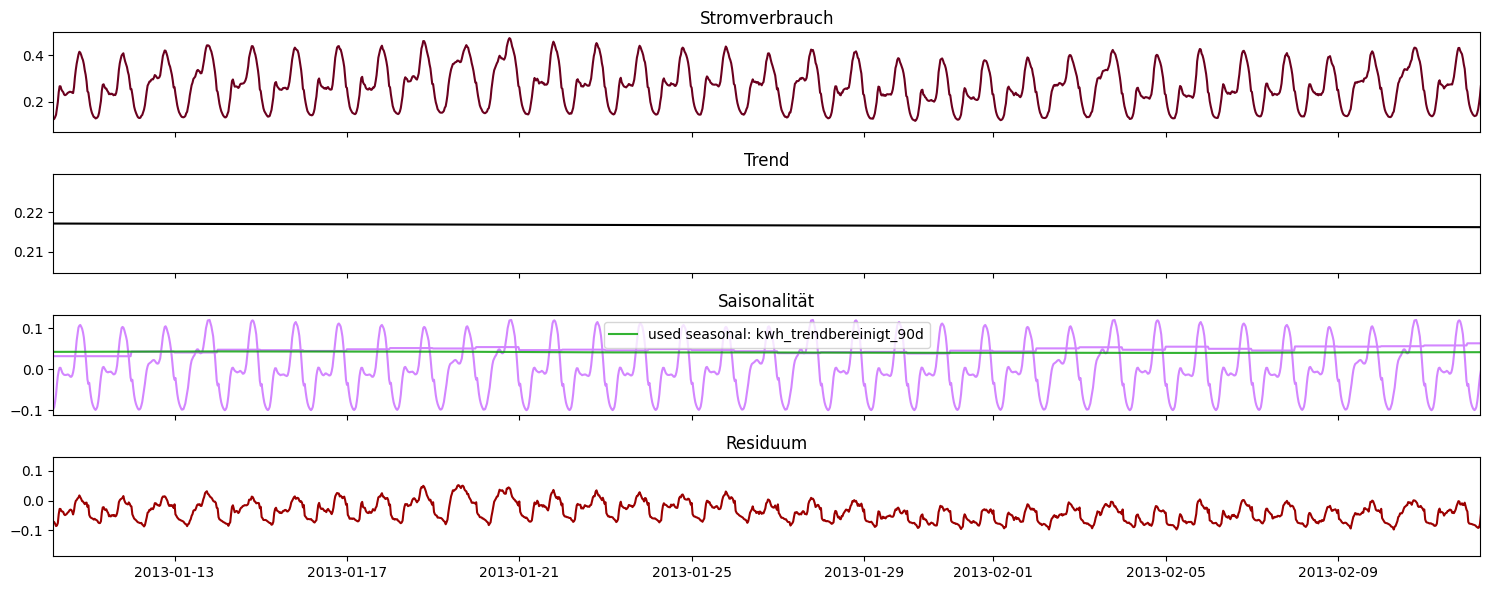

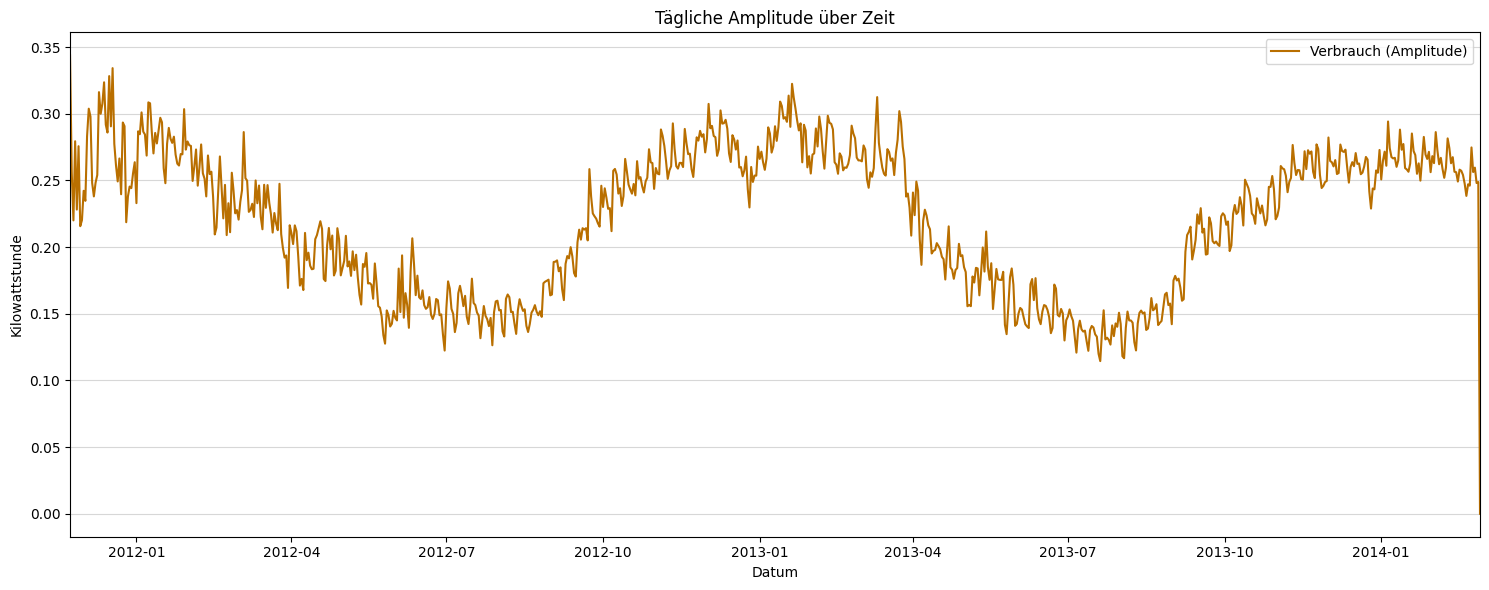

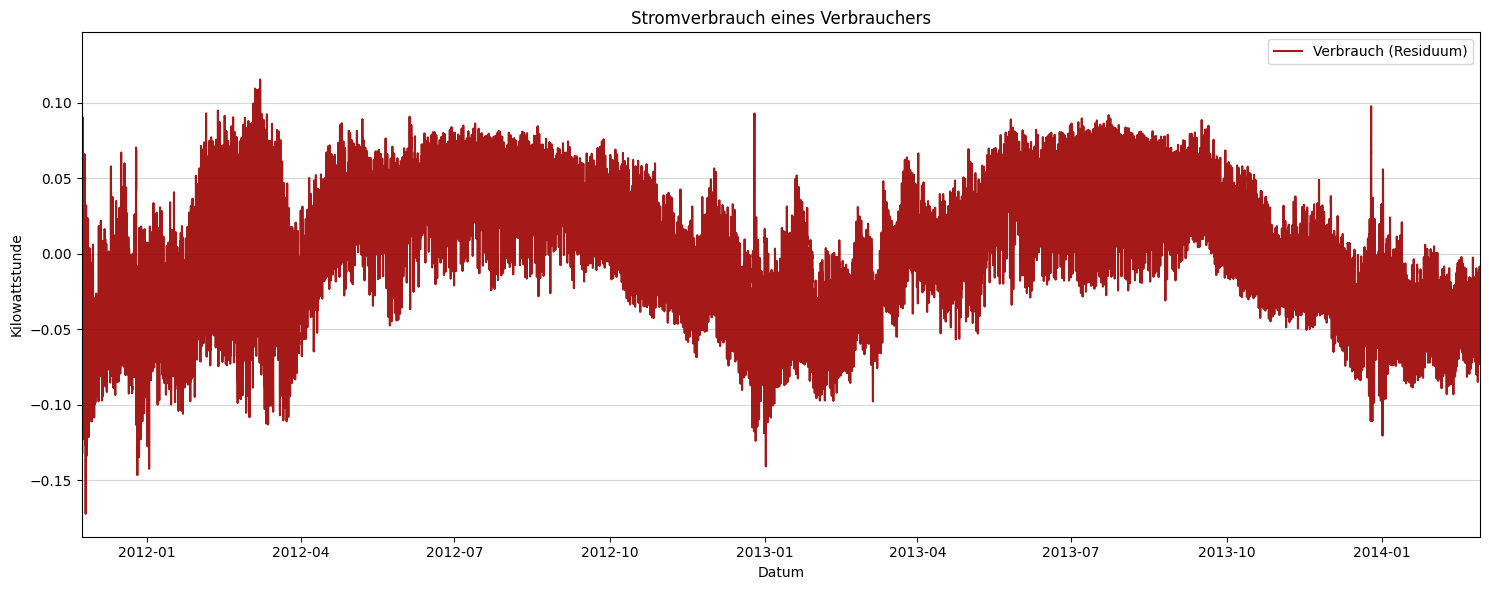

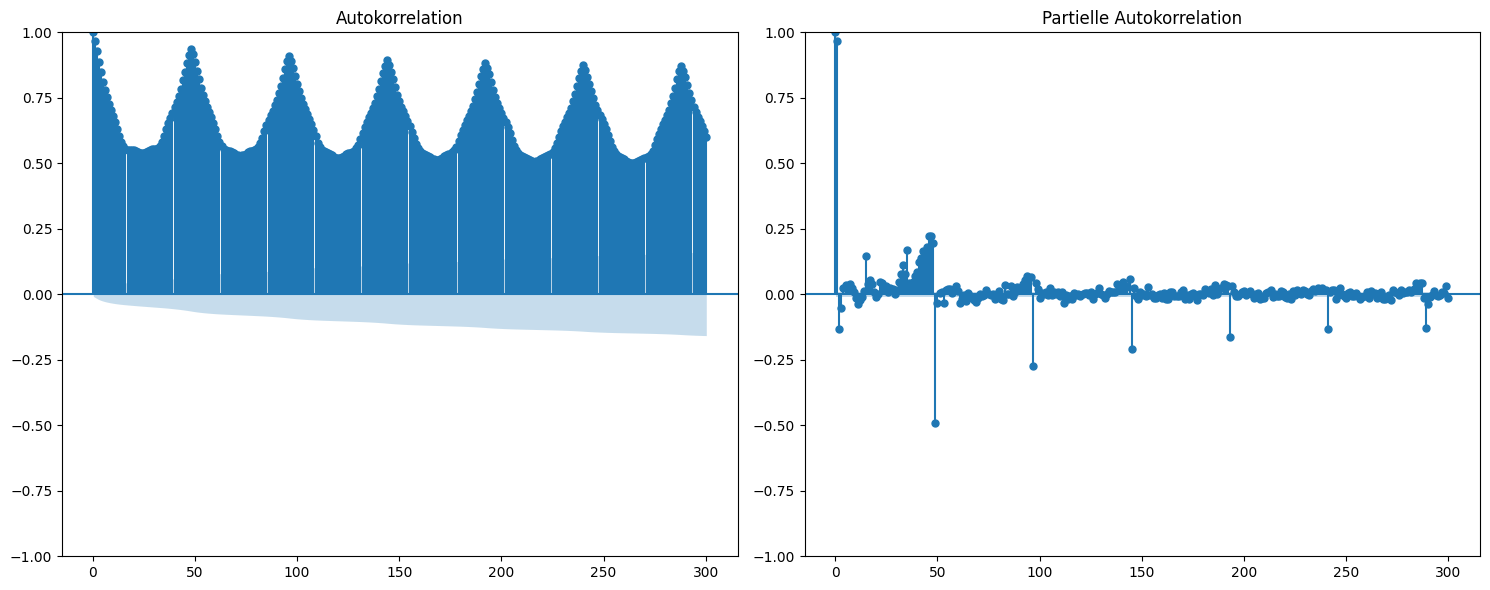

In [12]:
def analyse_cleaned(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Prefer ARIMA-derived seasonality if available, otherwise fall back to 90d or 3-month means
    if "kwh_trendbereinigt_arima_season" in df.columns:
        season_col = "kwh_trendbereinigt_arima_season"
    elif "kwh_trendbereinigt_90d" in df.columns:
        season_col = "kwh_trendbereinigt_90d"
    elif "kwh_trendbereinigt_3months" in df.columns:
        season_col = "kwh_trendbereinigt_3months"
    else:
        season_col = None

    if season_col is not None:
        df["kwh_bereinigt"] = (
            df["kwh_trendbereinigt"]
            - df["kwh_trendbereinigt_saison"]
            - df["kwh_trendbereinigt_saison_jahr"]
            - df[season_col]
        )
    else:
        # Fallback: if no seasonal estimate available, only remove week/day seasonality
        df["kwh_bereinigt"] = (
            df["kwh_trendbereinigt"]
            - df["kwh_trendbereinigt_saison"]
            - df["kwh_trendbereinigt_saison_jahr"]
        )

    # Getrennte Plots
    _, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.50), pd.Series(df.index).quantile(0.54))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(df["kwh_trend"], color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(df["kwh_trendbereinigt_saison"], color="#D386FF")
    ax[2].plot(df["kwh_trendbereinigt_saison_jahr"], color="#D386FF")
    if season_col is not None:
        ax[2].plot(df.index, df.get(season_col), color="#00A000", alpha=0.8, label=f"used seasonal: {season_col}")
        ax[2].legend()
    ax[2].set_title("Saisonalität")

    ax[3].plot(df["kwh_bereinigt"], color="#9B0000")
    ax[3].set_title("Residuum")

    plt.tight_layout()
    plt.show()

    # Tägliche Amplitude von kwh_trendbereinigt über Zeit
    plt.figure(figsize=(15, 6))
    amplitude = df.groupby(df.index.date)["kwh_trendbereinigt"].apply(lambda x: x.max() - x.min())
    plt.plot(amplitude, color="#B96F00", label="Verbrauch (Amplitude)")
    plt.title("Tägliche Amplitude über Zeit")
    plt.xlabel("Datum")
    plt.ylabel("Kilowattstunde")
    plt.grid(axis="y", alpha=0.5)
    plt.margins(x=0)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Residuum der gesamten Zeitreihe
    plt.figure(figsize=(15, 6))
    plt.plot(df.index, df["kwh_bereinigt"], color="#9B0000", alpha=0.9, label="Verbrauch (Residuum)")
    plt.title("Stromverbrauch eines Verbrauchers")
    plt.xlabel("Datum")
    plt.ylabel("Kilowattstunde")
    plt.grid(axis="y", alpha=0.5)
    plt.margins(x=0)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return df



df = analyse_cleaned(df)

plots_acf_pacf(df["kwh_bereinigt"])

# Jahressaisonalität rausgerechnet -> Offset Residuum korrigiert
# Ich weiß nicht ob sinnvoll, das es ja nur zwei Jahre gibt,
#   und daher für die meisten Tage nur ein Mittelwert von zwei Werten berechnet wird
# Vielleicht einfach hier so machen, und Berechnung über sin/cos beim Modell als Verbesserung anmerken

# Stärke/Amplitude vom Tagesmuster variiert saisonal (im Winter größere Schwankungen), daher weiterhin Tagesmuster erkennbar
# -> Behoben durch Skalierung mit Amplituden-Faktor? Doch zu aufwändig, vor allem für nur eine 6-Stunden Vorhersage, Erwähnung reicht


---

## STL / Autokorrelation und Partielle Autokorrelation

In [13]:
from statsmodels.tsa.seasonal import MSTL


def plot_STL(df: pd.DataFrame, periods: tuple) -> pd.DataFrame:
    decomposition = MSTL(df["kwh"], periods=periods)
    decomposition = decomposition.fit()

    _, ax = plt.subplots(4, 1, figsize=(15, 6), sharex=True)

    for p in ax:
        p.set_xlim(pd.Series(df.index).quantile(0.10), pd.Series(df.index).quantile(0.21))

    ax[0].plot(df["kwh"], color="#6B001E")
    ax[0].set_title("Stromverbrauch")

    ax[1].plot(decomposition.trend, color="#000000FF")
    ax[1].set_title("Trend")

    ax[2].plot(decomposition.seasonal, color="#D386FF")
    ax[2].set_title("Saisonalität")

    ax[3].plot(decomposition.resid, color="#9B0000")
    ax[3].set_title("Residuum")

    plt.tight_layout()
    plt.show()

    # Residuum der gesamten Zeitreihe
    plt.figure(figsize=(15, 6))
    plt.plot(df.index, decomposition.resid, color="#9B0000", alpha=0.9, label="Verbrauch (Bereinigt/Residuum)")
    plt.title("Stromverbrauch eines Verbrauchers")
    plt.xlabel("Datum")
    plt.ylabel("Kilowattstunde")
    plt.grid(axis="y", alpha=0.5)
    plt.margins(x=0)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return decomposition

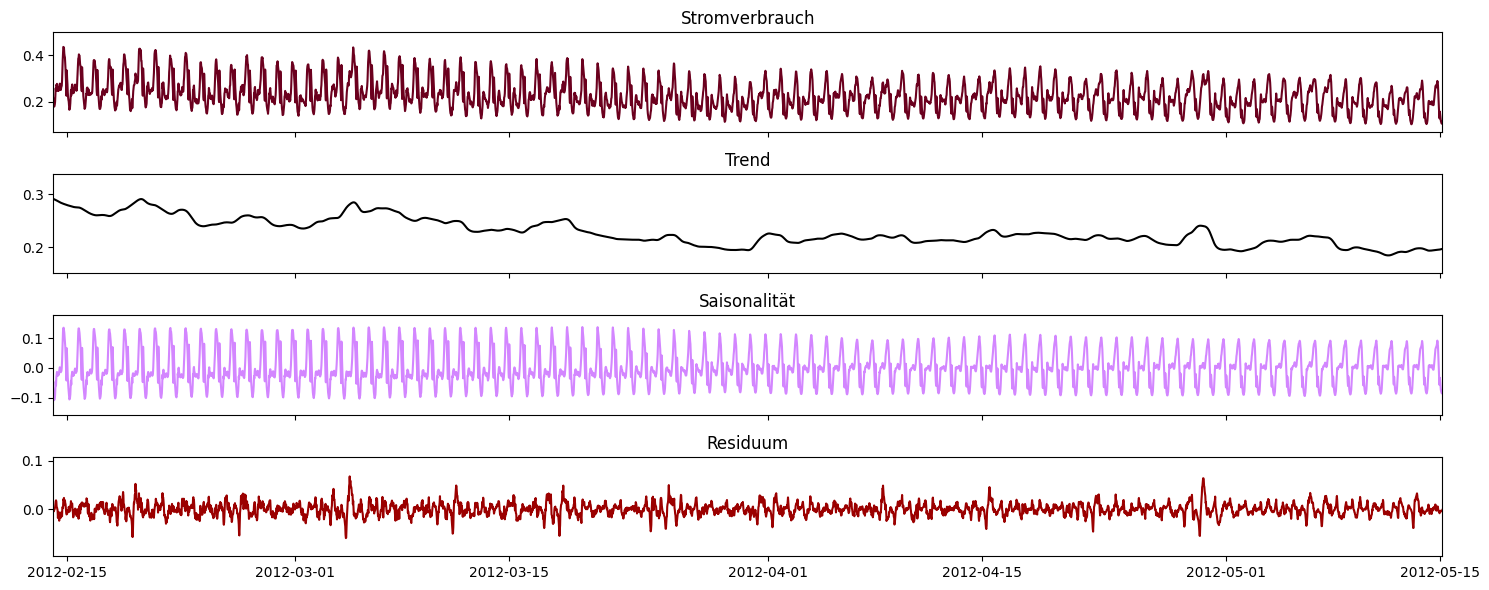

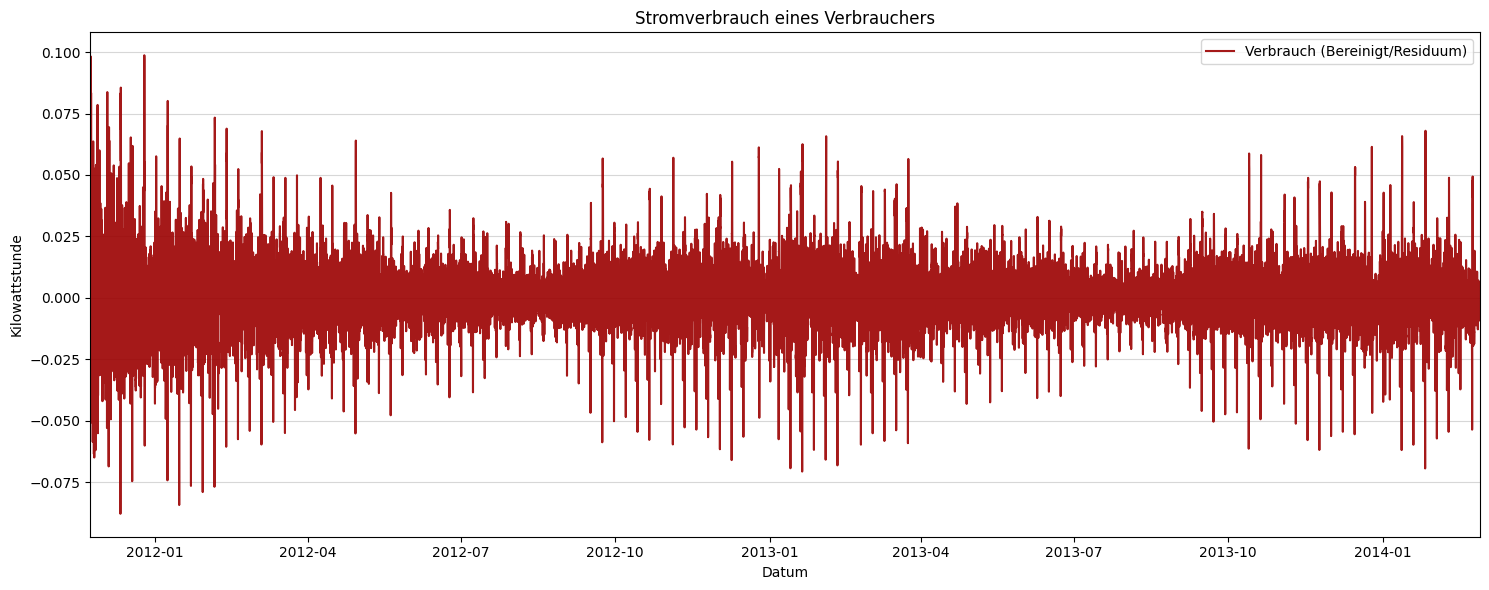

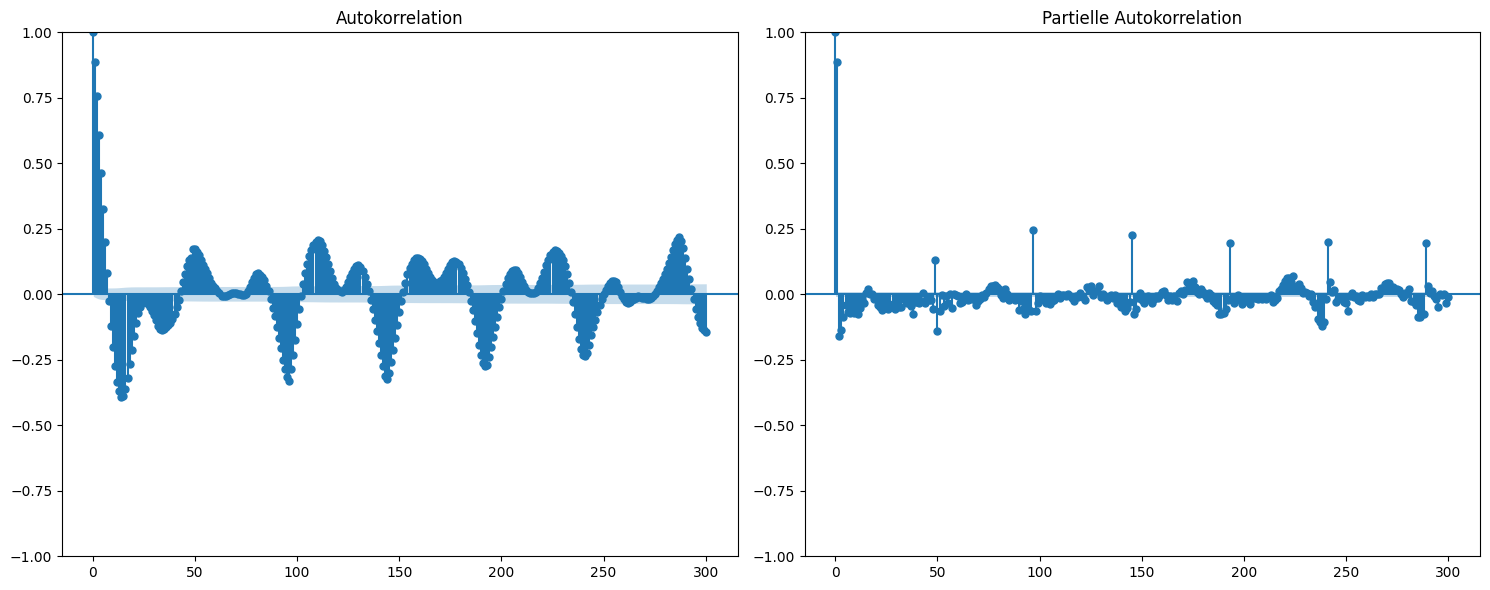

In [14]:
decomposition = plot_STL(df, (48))

plots_acf_pacf(decomposition.resid)

# Machen Sie verstehbar, welche Muster zu der negativen Autokorrelation der Residuen zu lags 12-15 führen
#   und wie Sie zustande kommen. Ggf. ergeben sich daraus dann Ideen, wie man die Zerlegung verbessern kann.

# ACF vom Resid zeigt noch Restmuster (Wellenform, negative Lags (-> daher Saisonalität; Falls ohne Vorzeichenwechsel -> nicht bereinigter Trend?))
# Jedenfalls Hinweis auf nicht erfasste Wochensaisonalität, siehe zweites ACF. Antwort formulieren in Markdown-Block.

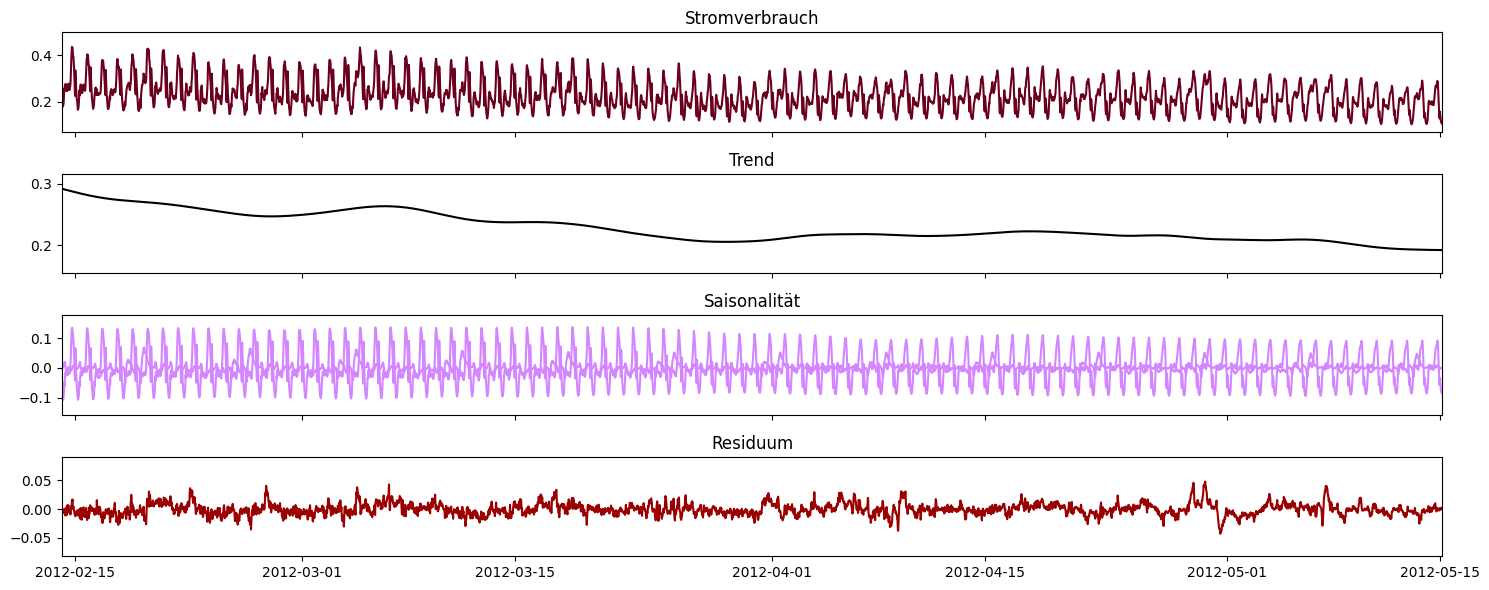

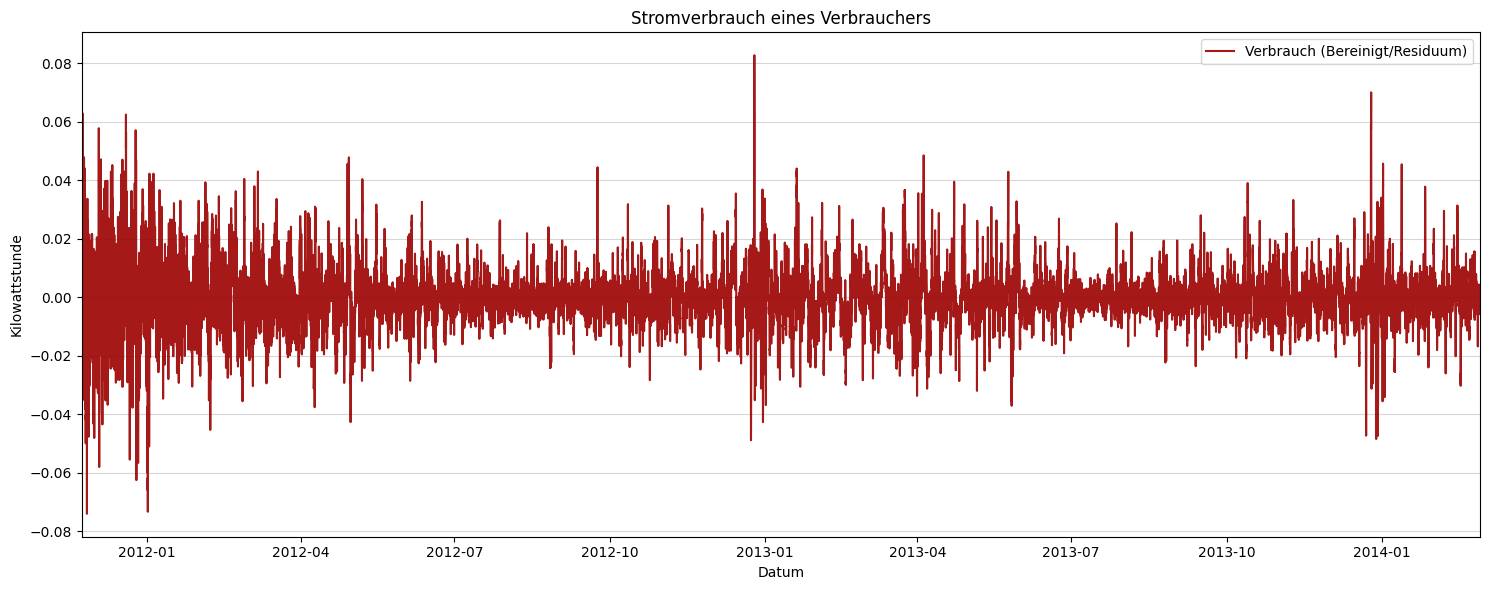

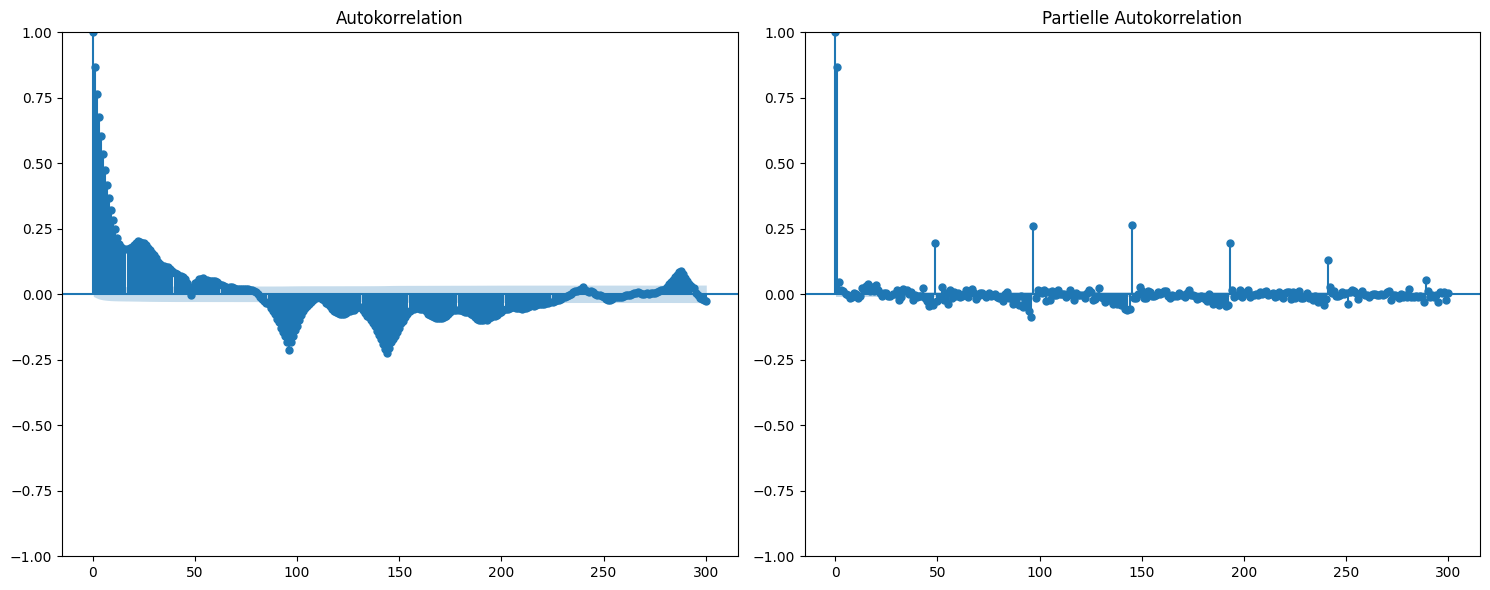

In [15]:
decomposition = plot_STL(df, (48, 336))  # Monat? Macht keinen Sinn; Jahr? Da nur zwei im Datensatz, zu wenig?

plots_acf_pacf(decomposition.resid)

---

## Vorhersage mit Linearer Regression

Da STL für seine Zerlegung auch Daten aus der Zukunft nimmt, würde die Weiterverwendung für das Training von Modellen Data Leakage einführen.

Deshalb werden für die Trainingsdaten wieder auf die manuelle Zerlegung zurückgegriffen.

In [ ]:
# Machen Sie verstehbar, warum die Prognosewerte stärker zu streuen scheinen, als die tatsächlichen Werte.
#   Und ob das so seine Richtigkeit hat.

# Vorschlag für Aufgabe 2:
# Erstes Modell entfernt zur Vereinfachung vom Notebook
# Ausführung von altem Modell als Vergleich (also nur Tag), dann mit Woche und zuletzt noch mit Jahressaisonalität als Feature

# TODO:
# Vielleicht LR mit MSTL versuchen, mit Hinweis auf Data Leakage (vernachlässigbar, da nur 6h?)
# Antwort in Markdown-Block

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error


def plot_pred(test: pd.DataFrame, pred: np.ndarray, col: str, title: str) -> None:
    plt.figure(figsize=(15, 6))
    plt.plot(test.index, test[col], color="#6B001E", alpha=0.5, linewidth=2, label="Tatsächlicher Verbrauch")
    plt.plot(test.index, pred, color="#0029BC", alpha=1, label="Prognose")
    plt.xlim(pd.Series(test.index).quantile(0.00), pd.Series(test.index).quantile(0.10))
    plt.title(title)
    plt.xlabel("Datum")
    plt.ylabel("Kilowattstunde")
    plt.grid(axis="y", alpha=0.5)
    plt.margins(x=0)
    plt.legend()
    plt.tight_layout()
    plt.show()


def show_metrics(y_test: np.ndarray, pred: np.ndarray, model: LinearRegression, verbose: bool = True) -> tuple[float, float, float, float]:
    r2 = r2_score(y_test, pred)
    mse = mean_squared_error(y_test, pred)
    rmse = root_mean_squared_error(y_test, pred)
    mae = mean_absolute_error(y_test, pred)

    if verbose:
        print(
            f"Regression Intercept:     {model.intercept_}\n"
            f"Regression Coefficients:  {model.coef_}\n"
            f"R²:                       {r2: .6f}\n"
            f"MSE:                      {mse: .6f}\n"
            f"RMSE:                     {rmse: .6f}\n"
            f"MAE:                      {mae: .6f}\n"
        )

    return r2, mse, rmse, mae

Als Zielvariable wird das Residuum 6 Stunden in der Zukunft verwendet.

Für die eigentliche Vorhersage werden der zuvor berechnete Trend und Saisonalität wieder einberechnet. 

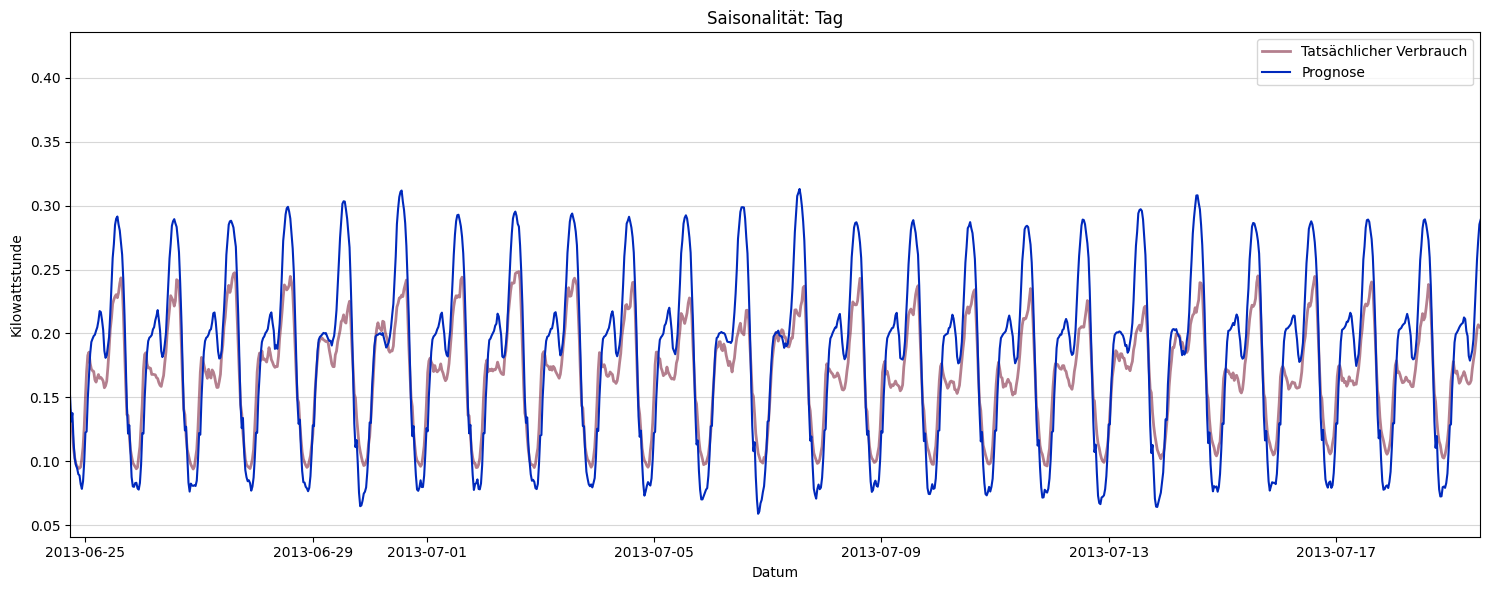

Regression Intercept:     -5.562951372837122e-06
Regression Coefficients:  [ 0.70935947 -0.08036727]
R²:                        0.791979
MSE:                       0.001122
RMSE:                      0.033491
MAE:                       0.027092

Vorhersage 6 Stunden in Zukunft: 0.1634 kWh


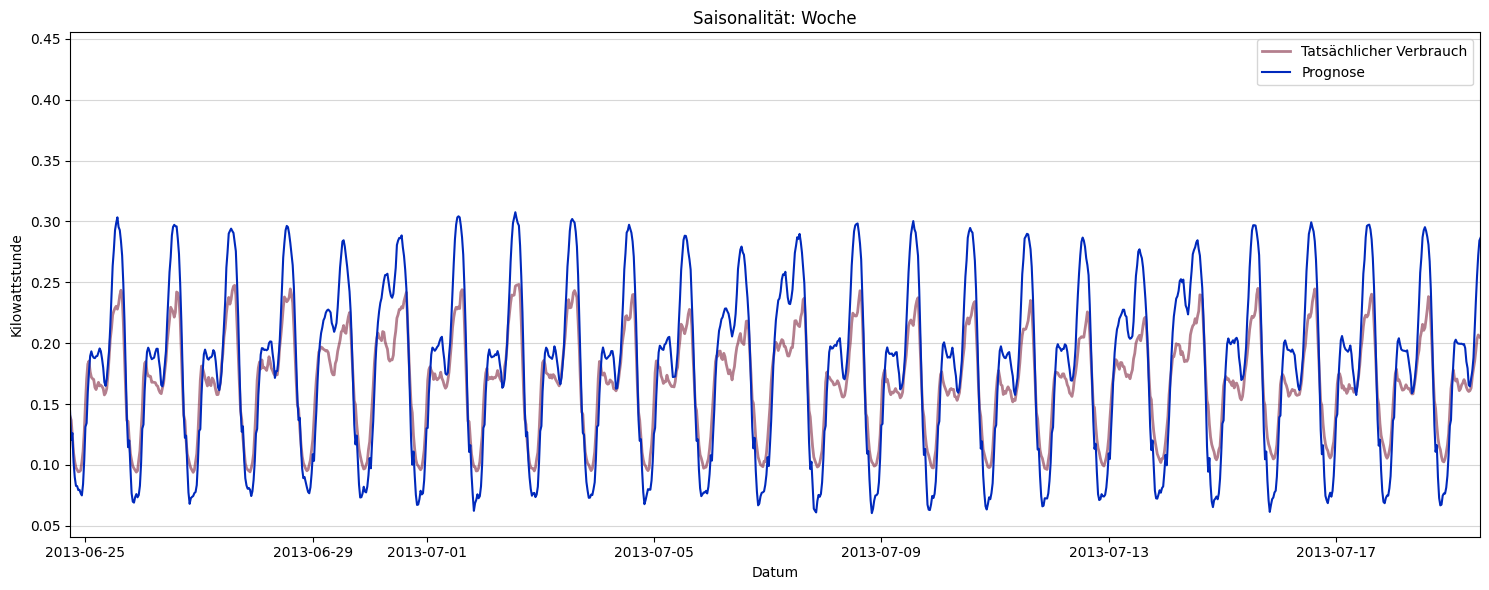

Regression Intercept:     -1.0675360374733264e-05
Regression Coefficients:  [ 0.71326537 -0.03010055]
R²:                        0.825872
MSE:                       0.000939
RMSE:                      0.030641
MAE:                       0.025276

Vorhersage 6 Stunden in Zukunft: 0.1714 kWh


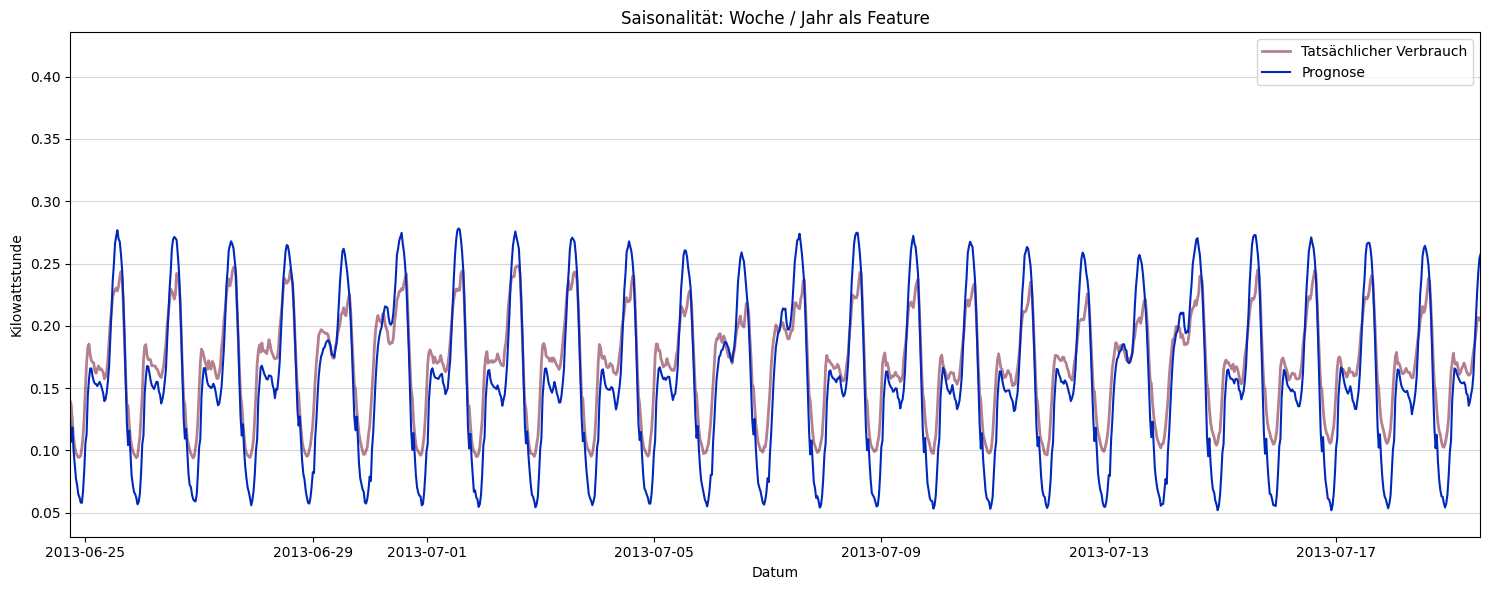

Regression Intercept:     -0.005352346933057335
Regression Coefficients:  [ 0.4741071  -0.27006753  0.01388478  0.03787824]
R²:                        0.885351
MSE:                       0.000618
RMSE:                      0.024863
MAE:                       0.020086

Vorhersage 6 Stunden in Zukunft: 0.1748 kWh


In [9]:
def linear_regression(df: pd.DataFrame, focus_week: bool = False, focus_year: bool = False, title: str = "") -> None:
    df_model = df.copy()

    # Train-Test-Split
    split = int(len(df_model) * 0.7)
    train = df_model.iloc[:split].copy()
    test = df_model.iloc[split:].copy()

    # Trend
    x_train = mdates.date2num(train.index)
    p = np.poly1d(np.polyfit(x_train, train["kwh"], 1))
    train["kwh_trend"] = p(mdates.date2num(train.index))
    test["kwh_trend"] = p(mdates.date2num(test.index))

    # Trendbereinigung
    train["kwh_trendbereinigt"] = train["kwh"] - train["kwh_trend"]
    test["kwh_trendbereinigt"] = test["kwh"] - test["kwh_trend"]

    # Saisonalität
    train["focus"] = (train.index.dayofweek * 48 if focus_week else 0) + train.index.hour * 2 + (train.index.minute // 30)
    seasonal = train.groupby("focus")["kwh_trendbereinigt"].mean()
    test["focus"] = (test.index.dayofweek * 48 if focus_week else 0) + test.index.hour * 2 + (test.index.minute // 30)
    train["kwh_saison"] = train["focus"].map(seasonal)
    test["kwh_saison"] = test["focus"].map(seasonal)

    # Alternativ Jahressaisonalität, aber hier nicht über Mittelwerte und nur als separate Features (wird also nicht rausgerechnet)
    if focus_year:
        train["sin_year"] = np.sin(2 * np.pi * train.index.dayofyear / 365.25)
        train["cos_year"] = np.cos(2 * np.pi * train.index.dayofyear / 365.25)
        test["sin_year"] = np.sin(2 * np.pi * test.index.dayofyear / 365.25)
        test["cos_year"] = np.cos(2 * np.pi * test.index.dayofyear / 365.25)
        year = ["sin_year", "cos_year"]
    else:
        year = []

    # Residuum
    train["kwh_bereinigt"] = train["kwh_trendbereinigt"] - train["kwh_saison"]
    test["kwh_bereinigt"] = test["kwh_trendbereinigt"] - test["kwh_saison"]

    # Aufteilung der Spalten nach Train und Test
    for split_df in [train, test]:
        split_df["kwh_bereinigt_t-1"] = split_df["kwh_bereinigt"].shift(1)
        # Trend und Saison bei t+12 – nur für Rekomposition, nicht als Features
        split_df["kwh_trend_t+12"] = split_df["kwh_trend"].shift(-12)
        split_df["kwh_saison_t+12"] = split_df["kwh_saison"].shift(-12)
        # Zielwerte
        split_df["kwh_target_bereinigt"] = split_df["kwh_bereinigt"].shift(-12)
        split_df["kwh_target"] = split_df["kwh"].shift(-12)

    last_row = test.iloc[[-1]].copy()
    future_time = last_row.index[0] + pd.Timedelta(hours=6)
    future_focus = (future_time.dayofweek * 48 if focus_week else 0) + future_time.hour * 2 + (future_time.minute // 30)
    last_row["kwh_trend_t+12"] = p(mdates.date2num([future_time]))[0]
    last_row["kwh_saison_t+12"] = seasonal.loc[future_focus]

    train = train.dropna()
    test = test.dropna()
    df_model = pd.concat([test, last_row])

    features = ["kwh_bereinigt", "kwh_bereinigt_t-1", *year]

    # Training (Residuum-Lags als Features (und alternativ Jahressaisonalität))
    X_train = train[features]
    y_train = train["kwh_target_bereinigt"]
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Vorhersage der Testdaten
    X_test = test[features]
    y_pred_residuum = model.predict(X_test)  # Nur das Residuum wird hier vorhergesagt

    # Trend und Saisonalität bei t+12 liegen durch .shift(-12) bereits im test-Index vor
    y_pred = y_pred_residuum + test["kwh_trend_t+12"] + test["kwh_saison_t+12"]
    plot_pred(test, y_pred, "kwh_target", title)
    _ = show_metrics(test["kwh_target"], y_pred, model)

    # Zukunftsprognose
    X_future = df_model.loc[[last_row.index[0]], features]
    future_residuum = model.predict(X_future)[0]
    y_pred = future_residuum + last_row["kwh_trend_t+12"].values[0] + last_row["kwh_saison_t+12"].values[0]

    print(f"Vorhersage 6 Stunden in Zukunft: {y_pred:.4f} kWh")


linear_regression(df, focus_week=False, title="Saisonalität: Tag")
linear_regression(df, focus_week=True, title="Saisonalität: Woche")
linear_regression(df, focus_week=True, focus_year=True, title="Saisonalität: Woche / Jahr als Feature")

## Varianzen

In [10]:
# Berechnung der Varianzen
def variances(df: pd.DataFrame):
    df_var = df.copy()

    df_var["trend"] = df_var["kwh_trend"]
    df_var["seasonal"] = df_var["kwh_trendbereinigt_saison"]
    df_var["resid"] = df_var["kwh_bereinigt"]

    variances = df_var[["kwh", "trend", "seasonal", "resid"]].var()
    variances["ryth"] = df_var["seasonal"].var()
    portions = variances / variances["kwh"]

    print(
        f"Von der Varianz der Zeitreihe werden:\n\t{(portions['trend'] * 100):2.1f}% durch den Trend erklärt"
        f"\n\t{(portions['ryth'] * 100):2.1f}% durch die Periodizität erklärt"
        f"\n\t{(portions['resid'] * 100):2.1f}% haben andere Ursachen (Residuum)"
    )


variances(df)

Von der Varianz der Zeitreihe werden:
	0.8% durch den Trend erklärt
	65.6% durch die Periodizität erklärt
	11.9% haben andere Ursachen (Residuum)
